# 4. Data Wrangling
Problem Statement: Data Wrangling on Real Estate Market<br>
Dataset: "RealEstate_Prices.csv"<br>
Description: The dataset contains information about housing prices in a specific real estate
market. It includes various attributes such as property characteristics, location, sale prices,
and other relevant features. The goal is to perform data wrangling to gain insights into the
factors influencing housing prices and prepare the dataset for further analysis or modeling.<br>
Tasks to Perform:
1. Import the "RealEstate_Prices.csv" dataset. Clean column names by removing spaces,
special characters, or renaming them for clarity.<br>
2. Handle missing values in the dataset, deciding on an appropriate strategy (e.g.,
imputation or removal).<br>
3. Perform data merging if additional datasets with relevant information are available
(e.g., neighborhood demographics or nearby amenities).<br>
4. Filter and subset the data based on specific criteria, such as a particular time period,
property type, or location.<br>
5. Handle categorical variables by encoding them appropriately (e.g., one-hot encoding or
label encoding) for further analysis.<br>
6. Aggregate the data to calculate summary statistics or derived metrics such as average
sale prices by neighborhood or property type.<br>
7. Identify and handle outliers or extreme values in the data that may affect the analysis
or modeling process.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt


In [5]:
# 1. LOAD DATASET
df = pd.read_csv("realestate_prices.csv")

In [6]:
# CLEAN COLUMN NAMES
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
df.head()

,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,...,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,...,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,...,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,...,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,...,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,...,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


In [8]:
# 2. REMOVE DUPLICATES
df = df.drop_duplicates()

In [9]:
# 3. HANDLE MISSING VALUES
df["price"] = pd.to_numeric(df["price"], errors="coerce")
df = df.dropna(subset=["price"])
df = df[df["price"] > 0]

for col in df.select_dtypes(include="number").columns:
    df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].fillna(df[col].mode()[0])
    df[col] = df[col].str.strip()

/tmp/ipykernel_10644/4206739850.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


In [10]:
# 4. REMOVE PRICE OUTLIERS
q1 = df["price"].quantile(0.25)
q3 = df["price"].quantile(0.75)
iqr = q3 - q1

df = df[df["price"].between(q1 - 1.5*iqr, q3 + 1.5*iqr)]

In [11]:
# 5. FILTER DATA
for col in ["property_type", "location", "neighborhood"]:
    if col in df.columns:
        choice = input("Enter " + col + " to filter (Enter to skip): ")
        if choice.strip():
            df = df[df[col].str.lower() == choice.strip().lower()]
            break


In [12]:
# 6. ENCODE CATEGORICAL DATA
df_encoded = pd.get_dummies(df, drop_first=True, dtype=int)

In [16]:
# 7. SUMMARY STATISTICS
print("\nDataset Summary:")
print(df.describe())

for col in ["property_type", "location", "neighborhood"]:
    if col in df.columns:
        print("\nAverage Price by", col)
        print(df.groupby(col)["price"].mean())


Dataset Summary:
                 id         price      bedrooms     bathrooms   sqft_living  \
count  2.046700e+04  2.046700e+04  20467.000000  20467.000000  20467.000000   
mean   4.603223e+09  4.769846e+05      3.329750      2.051632   1975.558167   
std    2.877364e+09  2.083713e+05      0.912885      0.711906    774.833460   
min    1.000102e+06  7.500000e+04      0.000000      0.000000    290.000000   
25%    2.131701e+09  3.150000e+05      3.000000      1.500000   1400.000000   
50%    3.905082e+09  4.375000e+05      3.000000      2.000000   1860.000000   
75%    7.338101e+09  6.000000e+05      4.000000      2.500000   2431.000000   
max    9.900000e+09  1.127500e+06     33.000000      7.500000   7480.000000   

           sqft_lot        floors    waterfront          view     condition  \
count  2.046700e+04  20467.000000  20467.000000  20467.000000  20467.000000   
mean   1.461041e+04      1.476035      0.002980      0.172668      3.406361   
std    4.010956e+04      0.537033

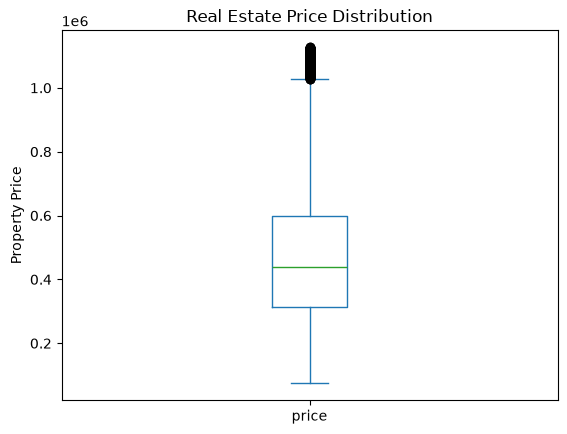

In [17]:
# 8. VISUALIZE PRICE DISTRIBUTION
df["price"].plot(kind="box", title="Real Estate Price Distribution")
plt.ylabel("Property Price")
plt.show()